# Day 03 — Crypto Market Anomaly Detector: analysis

**Business question:** Which days over the past year were genuinely unusual for Bitcoin, Ethereum and Solana — and how much should we trust the flag? Day 1 described *what happened* to prices and Day 2 measured *how risky it was to hold them*; Day 3 flags the specific days whose price–volume pattern stood out from each coin's own recent behaviour, explains each flag in plain language from the numbers on that day, and checks honestly how well the detector works.

**Method in one paragraph:** trailing 30-day z-scores (excluding today, so no future information leaks in) feed three transparent rules — R1 return shock (|return_z| ≥ 3), R2 volume surge (volume_z ≥ 3 and volume_ratio ≥ 2), R3 joint shock (|return_z| ≥ 2 and volume_z ≥ 2) — plus an Isolation Forest (contamination set from the baseline flag rate, random_state=42, n_estimators=200) on five per-coin-standardised features. There is no ground-truth manipulation label for real crypto data, so the detector is evaluated on 30 deliberately injected anomalies of known type, with a ±1-day tolerance. Flagged days are statistical outliers — **unusual patterns requiring investigation, never presented as proven manipulation**.

*Anomalies flagged here are statistical outliers in price and volume. They are not evidence of manipulation, and no flagged pattern should be presented as such. Educational analysis only — not investment advice.*


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def _find_root():
    """Resolve the project root from the notebook file's own location."""
    candidates = []
    try:
        candidates.append(Path(__file__).resolve().parent.parent)
        candidates.append(Path(__file__).resolve().parent)
    except NameError:
        pass  # Jupyter: __file__ is not defined; use cwd below.
    candidates.append(Path.cwd())
    candidates.append(Path.cwd().parent)
    for cand in candidates:
        if (cand / "data" / "processed" / "crypto_daily.csv").exists():
            return cand
    raise FileNotFoundError(
        "Could not locate data/processed/crypto_daily.csv from the "
        "notebook location or working directory; run this notebook "
        "from notebooks/ or the project root."
    )


ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
import anomaly as an  # noqa: E402

print('project root:', ROOT)
daily = pd.read_csv(ROOT / 'data/processed/crypto_daily.csv', parse_dates=['date'])
timeline = pd.read_csv(ROOT / 'data/processed/anomaly_timeline.csv', parse_dates=['date'])
injected = pd.read_csv(ROOT / 'data/processed/crypto_daily_injected.csv', parse_dates=['date'])
labels = pd.read_csv(ROOT / 'data/processed/injected_anomalies.csv')
source = json.loads((ROOT / 'data/processed/data_source.json').read_text())
print('data source:', source)
print('rows:', len(daily), '| coins:', sorted(daily['coin'].unique()))
print('window:', daily['date'].min().date(), 'to', daily['date'].max().date())
print('timeline flags:', len(timeline), '| injected labels:', len(labels))
LABELS = {'bitcoin': 'Bitcoin (BTC)', 'ethereum': 'Ethereum (ETH)', 'solana': 'Solana (SOL)'}
PALETTE = {'bitcoin': '#F7931A', 'ethereum': '#627EEA', 'solana': '#9945FF'}


project root: /home/hatch/workspace/goals/60-day-data-ai-portfolio/day-03-crypto-market-anomaly-detector
data source: {'source': 'live', 'generated_at_utc': '2026-11-07T15:54:55.049030+00:00', 'synthetic': False, 'seed': None, 'window': {'from': '2025-11-07', 'to': '2026-11-07'}, 'coins': ['bitcoin', 'ethereum', 'solana']}
rows: 1098 | coins: ['bitcoin', 'ethereum', 'solana']
window: 2025-11-07 to 2026-11-07
timeline flags: 54 | injected labels: 30


## Q1 — Which days were unusual, and why?

A day is **baseline-flagged** if any rule fires: **R1** (|return_z| ≥ 3, a move ≥ 3 trailing standard deviations from the coin's own recent mean), **R2** (volume_z ≥ 3 *and* volume at least double its 30-day average), or **R3** (both |return_z| ≥ 2 and volume_z ≥ 2 on the same day). Severity: **High** = R1 or R2 with |z| ≥ 4, or R1+R2 together; **Medium** = any single rule at threshold; **Low** = R3 only. The Isolation Forest flags a second set of days; the timeline below is the union of both methods. The first 30 days per coin are a warm-up with no z-scores (return_z is first valid on day 31; volume_z on day 60, because it needs 30 prior log-volume ratios), so the flaggable universe is 1,005 rows, not 1,098.


In [2]:
detected, contamination = an.run_detection(daily)
print(f"Contamination (baseline flag rate): {contamination:.4f}")
flaggable = detected['return_z'].notna().sum()
print(f"Flaggable rows: {flaggable} | baseline flags: {int(detected['baseline_flagged'].sum())} "
      f"({detected['baseline_flagged'].sum() / flaggable:.1%}) | "
      f"forest flags: {int(detected['is_anomaly'].sum())}")
print()
print("Flags per coin (timeline):")
print(timeline.groupby('coin').size())
print()
print("Flags by rule (a day can trigger several rules):")
for rule in ('R1', 'R2', 'R3'):
    print(f"  {rule}: {int(timeline['rules_triggered'].str.contains(rule).sum())}")
print()
print("Flags by severity:")
print(timeline.groupby('severity').size())
print()
print("Flags by month (concentration):")
print(timeline['date'].dt.strftime('%Y-%m').value_counts().sort_index())
print()
print("Most extreme flag per coin (largest |return_z|):")
for coin, g in timeline.groupby('coin'):
    top = g.loc[g['return_z'].abs().idxmax()]
    print(f"  {LABELS[coin]}: {top['date'].date()} {top['daily_return']:+.1%} "
          f"(z={top['return_z']:.1f}), vol {top['volume_ratio']:.1f}x, {top['severity']}")
print()
print("Top 5 flags by |return_z|:")
top5 = timeline.reindex(timeline['return_z'].abs().sort_values(ascending=False).index).head(5)
top5[['date', 'coin', 'daily_return', 'volume_ratio', 'return_z', 'volume_z', 'severity', 'flagged_by']]


Contamination (baseline flag rate): 0.0368
Flaggable rows: 1005 | baseline flags: 37 (3.7%) | forest flags: 39

Flags per coin (timeline):
coin
bitcoin     19
ethereum    18
solana      17
dtype: int64

Flags by rule (a day can trigger several rules):
  R1: 27
  R2: 11
  R3: 15

Flags by severity:
severity
High      10
Low       21
Medium    23
dtype: int64

Flags by month (concentration):
date
2025-12     1
2026-01     7
2026-02    16
2026-03     4
2026-06     7
2026-08    11
2026-09     2
2026-10     2
2026-11     4
Name: count, dtype: int64

Most extreme flag per coin (largest |return_z|):
  Bitcoin (BTC): 2026-08-20 +7.1% (z=5.8), vol 2.1x, High
  Ethereum (ETH): 2026-08-20 +17.5% (z=10.8), vol 3.8x, High
  Solana (SOL): 2026-08-20 +10.8% (z=6.6), vol 3.2x, High

Top 5 flags by |return_z|:


,date,coin,daily_return,volume_ratio,return_z,volume_z,severity,flagged_by
36,2026-08-20,ethereum,0.174982,3.842489,10.838289,4.912121,High,both
37,2026-08-20,solana,0.108195,3.183802,6.632978,6.036812,High,both
35,2026-08-20,bitcoin,0.071186,2.069844,5.794251,3.232066,High,both
11,2026-02-06,bitcoin,-0.140721,2.810324,-5.706801,1.096182,High,both
32,2026-06-06,ethereum,-0.105466,2.554834,-5.039062,3.247712,High,both


## Q2 — Do the two methods agree, and where do they disagree?

The forest's contamination was set equal to the baseline flag rate, so the two methods flag comparable *counts* — any difference is about *which* days, not how many. A day flagged by both deserves more confidence than a day flagged by only one. Forest-only flags get an explicit explanation: no single rule crossed its threshold, but the combination of return, volume and volatility was jointly unusual.


In [3]:
base = set(map(tuple, detected.loc[detected['baseline_flagged'], ['date', 'coin']].values))
forest = set(map(tuple, detected.loc[detected['is_anomaly'], ['date', 'coin']].values))
union = base | forest
print(f"Baseline flags: {len(base)} | Forest flags: {len(forest)} | Both: {len(base & forest)}")
print(f"Baseline-only: {len(base - forest)} | Forest-only: {len(forest - base)}")
print(f"Jaccard overlap (both / union): {len(base & forest) / len(union):.3f} (target >= 0.30)")
print()
print("Per coin:")
for coin in ('bitcoin', 'ethereum', 'solana'):
    b = {k for k in base if k[1] == coin}
    f = {k for k in forest if k[1] == coin}
    print(f"  {LABELS[coin]}: baseline {len(b)}, forest {len(f)}, both {len(b & f)}, "
          f"Jaccard {len(b & f) / len(b | f):.3f}")
print()
print("A forest-only flag, explained:")
print(timeline[timeline['flagged_by'] == 'forest'].iloc[0]['explanation'])
print()
print("A both-methods flag, explained:")
print(timeline[timeline['flagged_by'] == 'both'].iloc[0]['explanation'])


Baseline flags: 37 | Forest flags: 39 | Both: 22
Baseline-only: 15 | Forest-only: 17
Jaccard overlap (both / union): 0.407 (target >= 0.30)

Per coin:
  Bitcoin (BTC): baseline 14, forest 13, both 8, Jaccard 0.421
  Ethereum (ETH): baseline 13, forest 13, both 8, Jaccard 0.444
  Solana (SOL): baseline 10, forest 13, both 6, Jaccard 0.353

A forest-only flag, explained:
Ethereum rose 6.2% on 2025-12-10 — flagged by the Isolation Forest only (return z = 1.8, volume 1.2x its 30-day average, 30-day volatility 68% annualised); no single rule crossed its threshold, but the combination was jointly unusual.

A both-methods flag, explained:
Bitcoin rose 4.6% on 2026-01-14 (return z = 3.6) while volume ran 1.7x its 30-day average — a sharp price move well outside its recent range.


## Q3 — How good is the detector, really?

There is no ground-truth manipulation label for real crypto data, so evaluation is on **30 injected anomalies** of known type, built from each coin's trailing 30-day window ending the day before the injection: 10 price spikes (return set to +4.0 × the trailing return std), 10 volume surges (volume set to 5.0 × the trailing mean volume), 10 joint shocks (return +3.0 × trailing std and volume 5.0 × trailing mean volume), spread across the three coins with at most one per calendar month per coin. The identical pipeline runs on the injected copy; a flag within **±1 day** of an injection counts as detecting it (a one-day price spike mechanically moves the next day's return too). A mandatory harness self-check asserts every planted anomaly clears its target rule's bar on the injected frame — a plant that is not anomalous relative to history is a harness bug, not a detector miss. Precision counts a flag as a true positive if it matches an injection **or** a flag the detector also raises on the clean (uninjected) data, because the injected copy still contains all 54 genuine unusual real days; only a flag matching neither is a false positive.


In [4]:
inj_detected, _c = an.run_detection(injected)
ev = an.evaluate(inj_detected, labels, tolerance_days=1, clean_flags=timeline[['date', 'coin']])
for method in ('baseline', 'forest', 'union'):
    m = ev[method]
    print(f"{method:10s} precision {m['precision']:.3f}  recall {m['recall']:.3f}  "
          f"F1 {m['f1']:.3f}  (TP {m['tp']}/{ev['n_injected']}, FP {m['fp']}, flags {m['n_flags']})")
print()
print("Per-type recall (union):", {k: round(v, 2) for k, v in ev['per_type_recall'].items()})
print(f"Jaccard (injected run): {ev['jaccard']:.3f}")
print()
targets = [
    ("Union recall >= 0.80", ev['union']['recall'] >= 0.80),
    ("Union precision >= 0.50", ev['union']['precision'] >= 0.50),
    ("Per-type recall >= 0.60 each", all(v >= 0.60 for v in ev['per_type_recall'].values())),
]
for name, passed in targets:
    print(f"  {'PASS' if passed else 'FAIL'}  {name}")
print()
print("Which injected anomalies did the union miss?")
found = set()
uf = inj_detected[inj_detected['baseline_flagged'] | inj_detected['is_anomaly']]
for _, inj in labels.iterrows():
    near = uf[(uf['coin'] == inj['coin'])
              & ((pd.to_datetime(uf['date']) - pd.to_datetime(inj['date'])).abs().dt.days <= 1)]
    if len(near):
        found.add((str(inj['date']), inj['coin']))
missed = labels[[(str(d), c) not in found for d, c in zip(labels['date'], labels['coin'])]]
missed


baseline   precision 1.000  recall 1.000  F1 1.000  (TP 30/30, FP 0, flags 60)
forest     precision 0.967  recall 0.733  F1 0.834  (TP 22/30, FP 2, flags 60)
union      precision 0.974  recall 1.000  F1 0.987  (TP 30/30, FP 2, flags 78)

Per-type recall (union): {'joint_shock': 1.0, 'price_spike': 1.0, 'volume_surge': 1.0}
Jaccard (injected run): 0.538

  PASS  Union recall >= 0.80
  PASS  Union precision >= 0.50
  PASS  Per-type recall >= 0.60 each

Which injected anomalies did the union miss?


,date,coin,type,magnitude,construction


## Manual validation — one flagged day recomputed by hand

Ethereum on 2026-08-20 rose 17.5% (return z = 10.84, volume 3.8× its 30-day average) — the most extreme flag in the window. Recomputing its return_z from `crypto_daily.csv` by hand: trailing 30-day mean and standard deviation of daily returns before that day, excluding today.


In [5]:
eth = daily[daily['coin'] == 'ethereum'].sort_values('date').reset_index(drop=True)
idx = int(eth.index[eth['date'] == '2026-08-20'][0])
prior = eth['daily_return'].iloc[idx - 30:idx]
recomputed = (eth['daily_return'].iloc[idx] - prior.mean()) / prior.std(ddof=1)
published = timeline[(timeline['coin'] == 'ethereum') & (timeline['date'] == '2026-08-20')]['return_z'].iloc[0]
print(f"Prior 30-day mean return: {prior.mean():.6f} | std: {prior.std(ddof=1):.6f}")
print(f"Return on the day: {eth['daily_return'].iloc[idx]:.6f}")
print(f"Recomputed return_z: {recomputed:.6f} | published: {published:.6f} | diff: {abs(recomputed - published):.2e}")
assert abs(recomputed - published) <= 1e-9
print('Manual validation passes (diff <= 1e-9).')


Prior 30-day mean return: 0.000927 | std: 0.016059
Return on the day: 0.174982
Recomputed return_z: 10.838289 | published: 10.838289 | diff: 1.78e-15
Manual validation passes (diff <= 1e-9).


## Charts

The four charts in `outputs/charts/` (regenerated offline by `python -m src.make_charts` from the committed CSVs). All are drawn to scale, with titles, labelled axes and a "Powered by CoinGecko" source note.


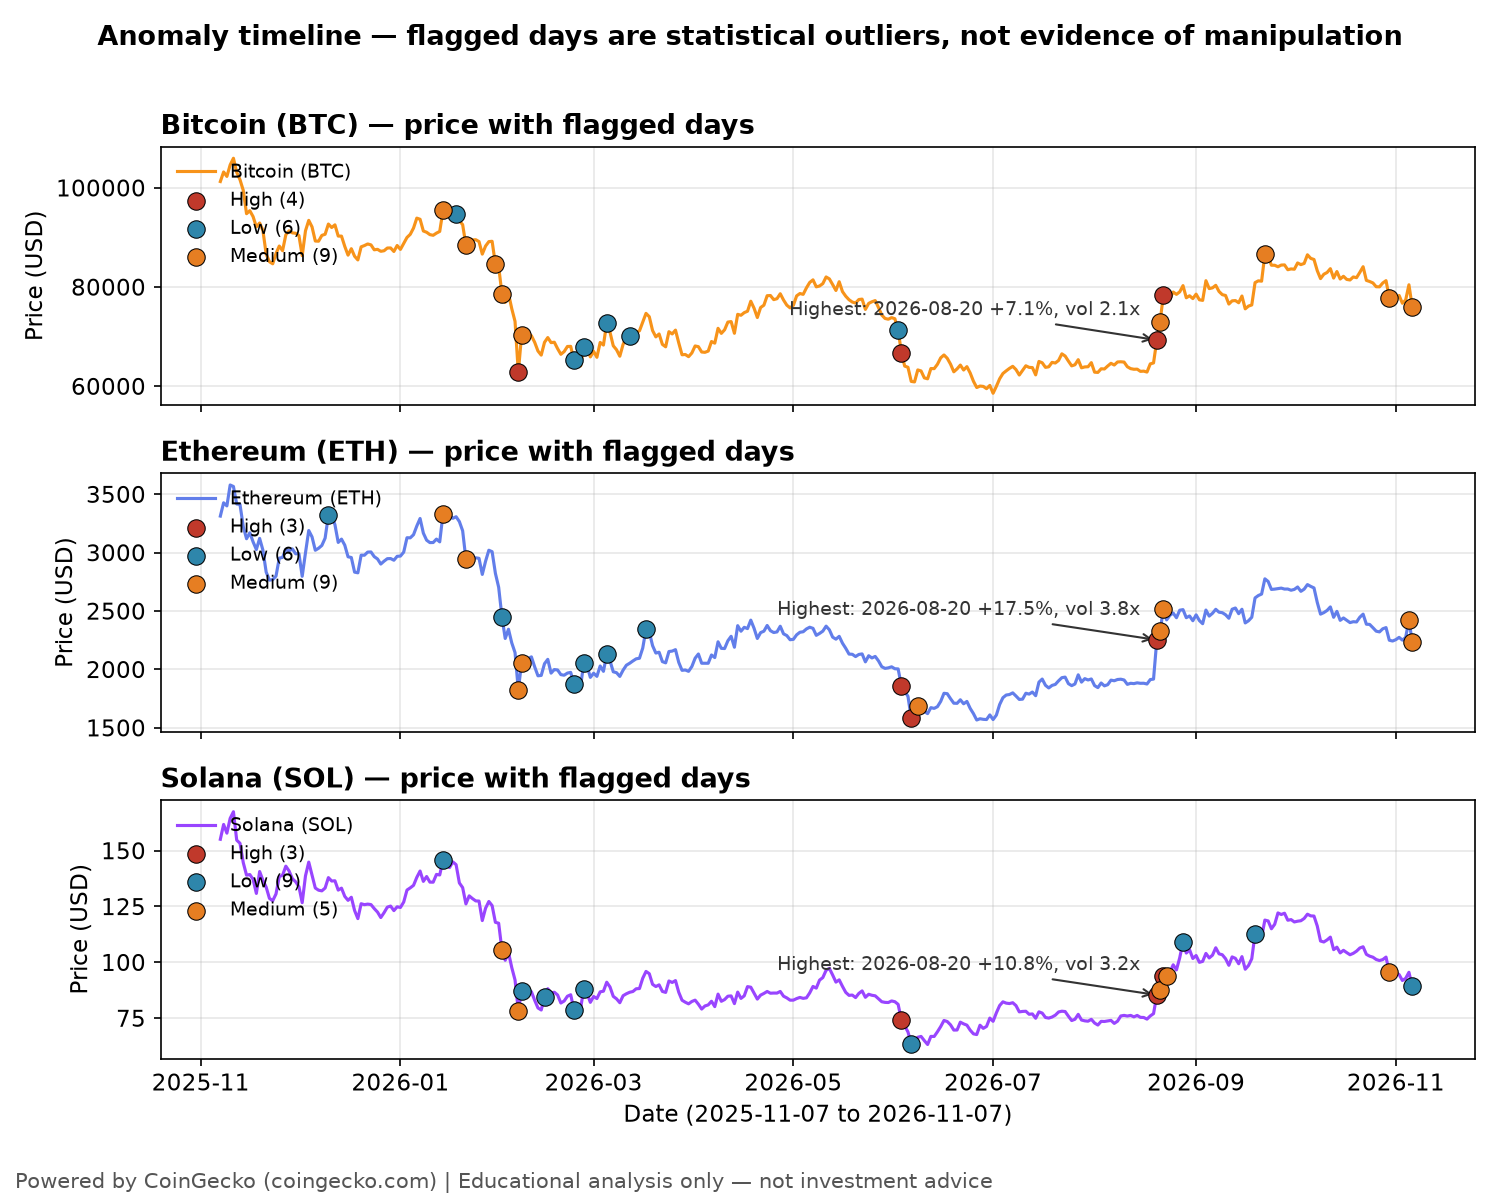

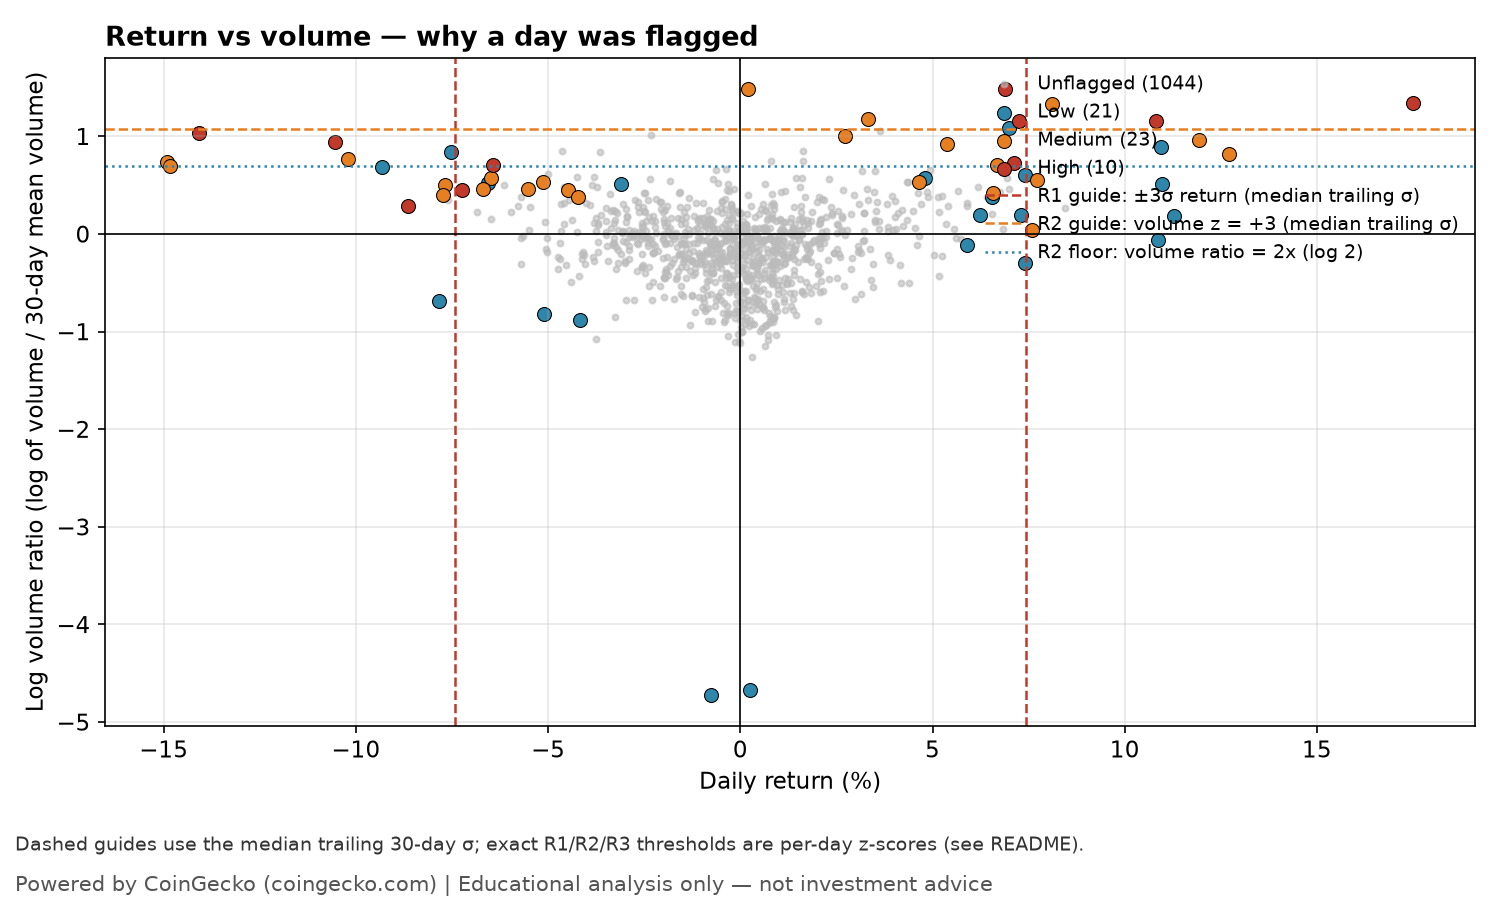

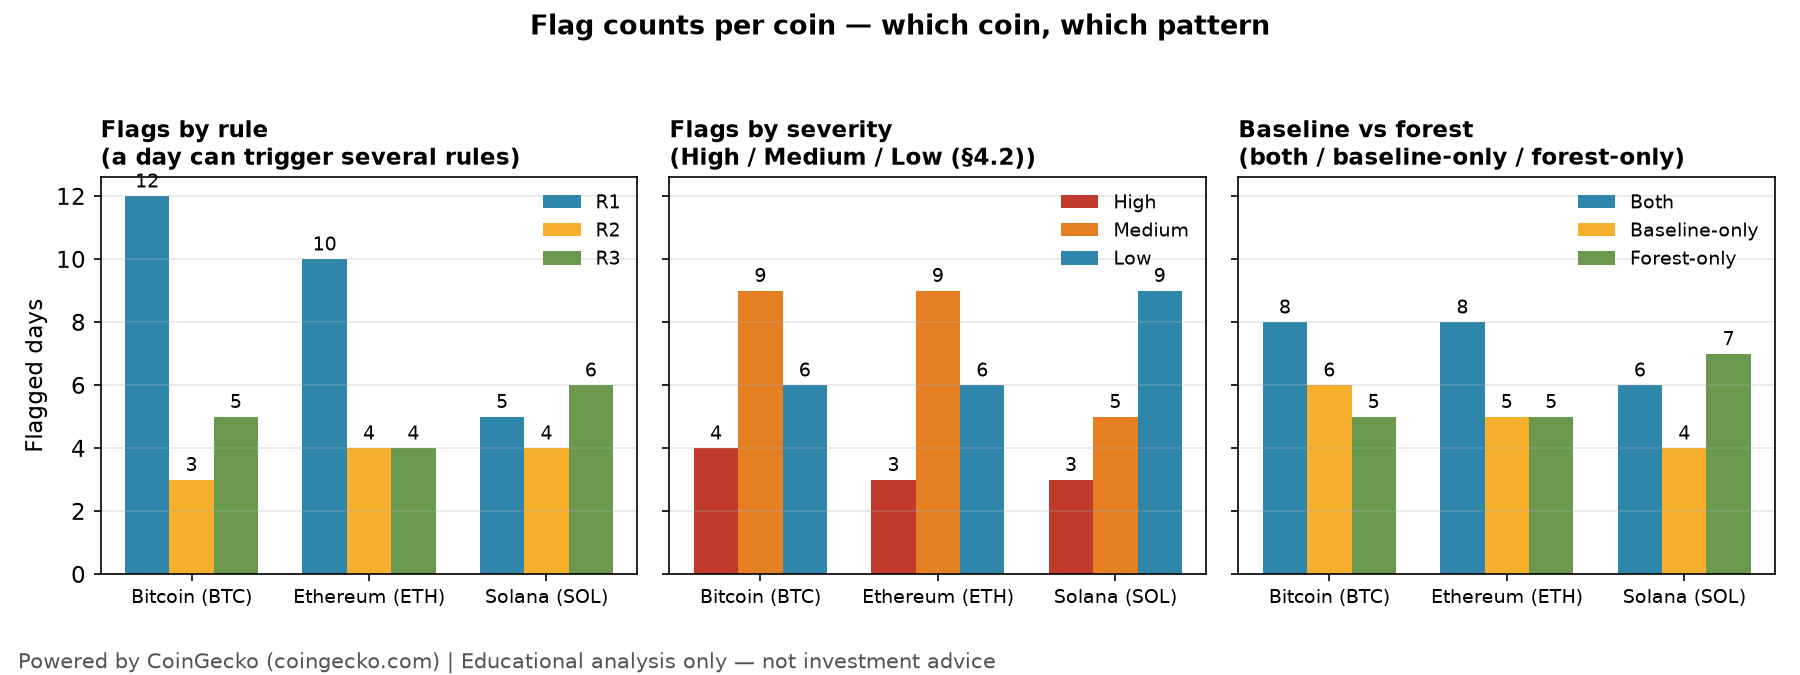

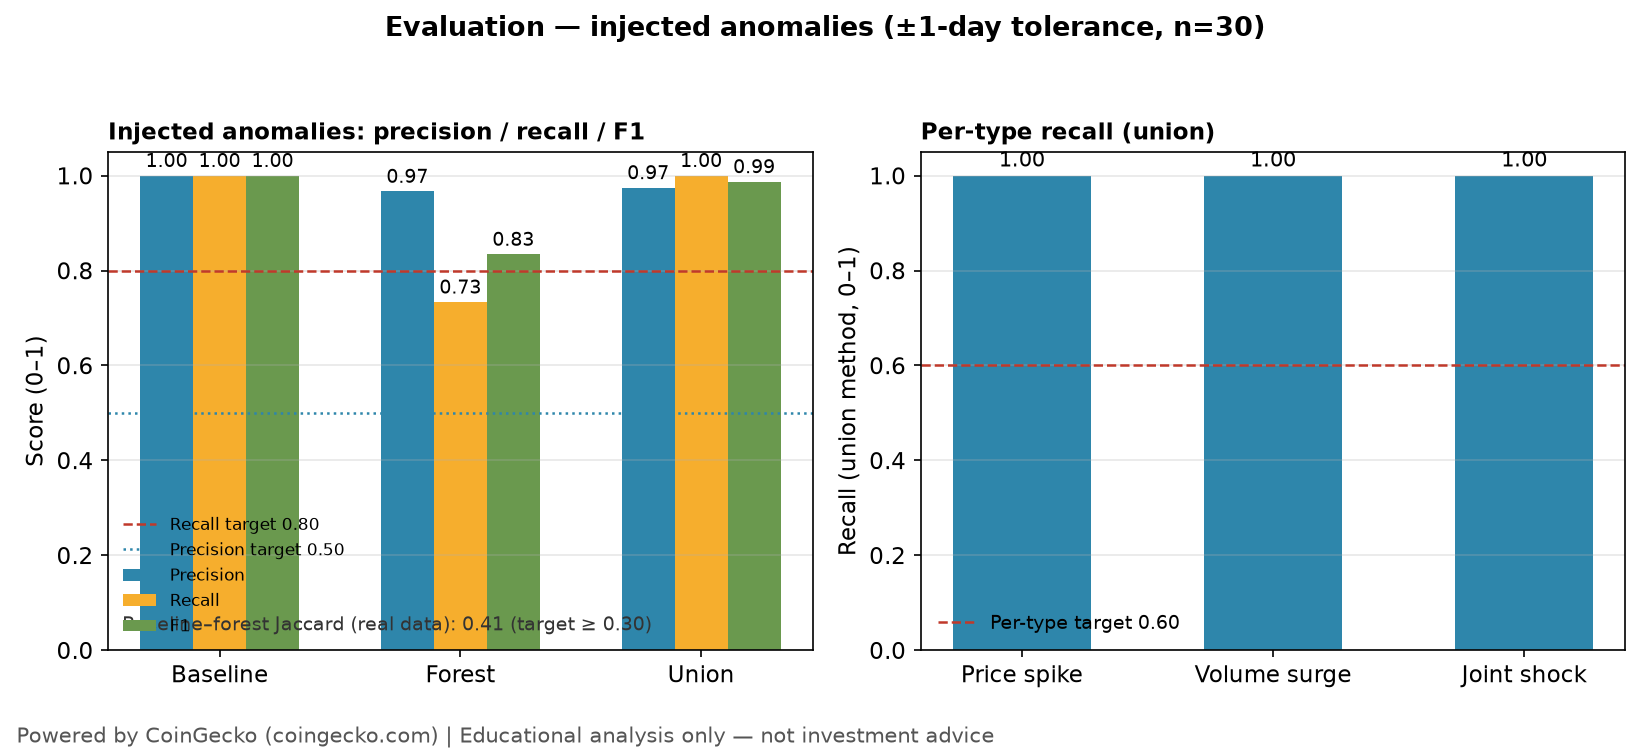

In [6]:
from IPython.display import Image, display
for name in ('01_anomaly_timeline', '02_return_volume_scatter',
             '03_flag_counts_severity', '04_evaluation'):
    display(Image(filename=str(ROOT / 'outputs' / 'charts' / f'{name}.png')))


## Summary

- **54 flagged days** out of 1,005 flaggable rows (5.4% of the union; baseline alone 37 days, 3.7% — inside the 2–5% sanity band). Bitcoin had the most flags (19), then Ethereum (18), then Solana (17) — the flags were spread fairly evenly across the three coins.
- **Flags clustered in February 2026 (16 of 54) and August 2026 (11 of 54)**, the two sharpest stretches of the year; the single most extreme day for all three coins was **2026-08-20** (ETH +17.5%, z = 10.8, volume 3.8×).
- **The methods substantially agree** (Jaccard 0.41 on real data, target ≥ 0.30): 22 days flagged by both, 15 baseline-only, 17 forest-only.
- **On injected anomalies the union finds 30 of 30 (recall 1.00, target ≥ 0.80 — PASS)** with per-type recall 1.00 / 1.00 / 1.00 and precision 0.974 (76 of 78 flags are injected anomalies or genuine unusual days also flagged on clean data; target ≥ 0.50 — PASS). The baseline rules alone also find all 30 (precision 1.00); the forest alone finds 22 of 30 (recall 0.73) and misses only volume surges — a single high-volume day with an ordinary return is not, on its own, among the most anomalous days on the forest's five features. The detector is good at *finding* unusual patterns and honest about *trusting* them: treat any single flag as a starting point for investigation, not a conclusion.
- **Limits:** fixed ±3σ rules over-flag in volatile regimes and under-flag in calm ones; forest scores are relative rankings, not probabilities; 365 days per coin is a small sample for unsupervised learning; the model cannot distinguish a genuine market event from a data error or from manipulation — it flags statistical unusualness only.
